# Workshop #2: Silver Layer Parquet Exploration & Verification
**Course:** Data Analysis Programming — Semester 2026-I  
**Professor:** Eng. Carlos Andrés Sierra, M.Sc.  
**Institution:** Universidad Distrital Francisco José de Caldas  
**Team 7:** Samuel Alberto Leal Saenz, Cristian Andres Gámez Nuñez, Sara Nicolle Martínez Moreno  
**Topic:** Landslide Monitoring and Risk in Colombia

---

## 1. Introduction and Objectives
This notebook demonstrates how to load, inspect, and evaluate the standardized **Silver Layer Parquet files** generated by the Apache Airflow processing pipeline.

In this notebook, we verify:
1. **Schema Enforcement & PyArrow Metadata:** Correct data types (UTC timestamps, floats, categories).
2. **Null Handling & Imputation:** Audit of missing values and sentinel/imputation flags.
3. **Outlier Detection Analysis:** Statistical evaluation using IQR and Z-score methods.
4. **NLP Text Preprocessing Audit:** Token frequencies, stopword removal, and vocabulary in disaster narratives.
5. **End-to-End Data Lineage:** Verification of `_bronze_source_file`, `_processed_at_utc`, and deterministic `_record_hash`.


In [1]:
import pathlib
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import numpy as np
import json

SILVER_DIR = pathlib.Path('../datalake_silver')
if not SILVER_DIR.exists():
    SILVER_DIR = pathlib.Path('datalake_silver')

parquet_files = sorted(list(SILVER_DIR.glob('*.parquet')))
print(f'Total Silver Parquet files detected: {len(parquet_files)}')
for f in parquet_files:
    print(f' - {f.name} ({f.stat().st_size / 1024:.1f} KB)')


Total Silver Parquet files detected: 5
 - landslides_20261121_070012.parquet (170.4 KB)
 - lhasa_hazard_20261121_070012.parquet (10.7 KB)
 - rainfall_20261121_070012.parquet (99.8 KB)
 - rainfall_20261121_071742.parquet (100.2 KB)
 - rainfall_historical_20261121_070012.parquet (2546.9 KB)


## 2. Inspecting Rainfall Silver Data (`rainfall_*.parquet`)
We select the latest rainfall Parquet file and inspect its schema, column types, and embedded PyArrow metadata.


In [2]:
# 'rainfall_2...' excludes the 'rainfall_historical_...' (ERA5) files
rainfall_files = [f for f in parquet_files if f.name.startswith('rainfall_2')]
assert len(rainfall_files) > 0, 'No rainfall parquet file found'
target_rainfall = rainfall_files[-1]

# Read PyArrow schema metadata
schema_meta = pq.read_metadata(target_rainfall)
print('--- PyArrow File Metadata ---')
print(f'Rows: {schema_meta.num_rows:,}')
print(f'Columns: {schema_meta.num_columns}')
print(f'Custom Metadata: {schema_meta.metadata}')

# Load into Pandas
df_rain = pd.read_parquet(target_rainfall)
print('\n--- DataFrame Info ---')
print(df_rain.info())
df_rain.head()


--- PyArrow File Metadata ---
Rows: 2,400
Columns: 16
Custom Metadata: {b'ARROW:schema': b'/////ygPAAAUAAAAAAAAAAAACgAOAAYABQAIAAoAAAAAAQQAEAAAAAAACgAMAAAABAAIAAoAAADsCgAABAAAAAgAAADEAQAAOAEAAAABAADUAAAAqAAAAFwAAAAwAAAABAAAAGT+//8QAAAABAAAAAIAAAAxNgAADAAAAGNvbHVtbl9jb3VudAAAAACM/v//FAAAAAQAAAAEAAAAMjQwMAAAAAAJAAAAcm93X2NvdW50AAAAtP7//zAAAAAEAAAAIAAAADIwMjYtMTEtMjFUMDc6MTc6NDIuMTE5NTkzKzAwOjAwAAAAAA4AAABjcmVhdGVkX2F0X3V0YwAA/P7//xgAAAAEAAAACAAAAHJhaW5mYWxsAAAAAAUAAAB0b3BpYwAAACT///8UAAAABAAAAAQAAAAyNDAwAAAAAAoAAAByb3dzX2NvdW50AABM////IAAAAAQAAAASAAAAb3Blbm1ldGVvX2ZvcmVjYXN0AAAJAAAAc291cmNlX2lkAAAAgP///2QAAAAEAAAAVgAAAFsib3Blbm1ldGVvX2ZvcmVjYXN0XzIwMjYxMTIxXzA3MTEzOC5qc29uIiwgIm9wZW5tZXRlb19mb3JlY2FzdF8yMDI2MTEyMV8wNzE3MTUuanNvbiJdAAATAAAAYnJvbnplX3NvdXJjZV9maWxlcwAIAAwABAAIAAgAAAAMCQAABAAAAP0IAAB7ImluZGV4X2NvbHVtbnMiOiBbXSwgImNvbHVtbl9pbmRleGVzIjogW10sICJjb2x1bW5zIjogW3sibmFtZSI6ICJzdGF0aW9uX25hbWUiLCAiZmllbGRfbmFtZSI6ICJzdGF0aW9uX25hbWUiLCAicGFuZGFzX3R5cGUiOiAiY2F0ZWdvcmljYWwiLCAibnVtc

,station_name,department,latitude,longitude,elevation_m,precipitation_mm,rain_mm,soil_moisture_m3m3,timestamp,soil_moisture_imputed,precip_outlier_iqr,precip_outlier_zscore,precip_zscore,_bronze_source_file,_processed_at_utc,_record_hash
0,Bogota,Cundinamarca,4.674868,-74.11331,2582.0,0.1,0.0,0.146,2026-11-19 00:00:00+00:00,False,False,False,-0.771,openmeteo_forecast_20261121_071138.json,2026-11-21 07:17:42.022289+00:00,16c35a6962eb35a66b11fee1e12ba95537c862553ee4c6...
1,Bogota,Cundinamarca,4.674868,-74.11331,2582.0,0.0,0.0,0.147,2026-11-19 01:00:00+00:00,False,False,False,0.000,openmeteo_forecast_20261121_071138.json,2026-11-21 07:17:42.022289+00:00,362f9399719973a96a582d7dfecb628c79d7078e280e28...
2,Bogota,Cundinamarca,4.674868,-74.11331,2582.0,0.0,0.0,0.147,2026-11-19 02:00:00+00:00,False,False,False,0.000,openmeteo_forecast_20261121_071138.json,2026-11-21 07:17:42.022289+00:00,eec5f9313691443efcc3cc2a60f9d296c030ceffb9ffcf...
3,Bogota,Cundinamarca,4.674868,-74.11331,2582.0,0.0,0.0,0.147,2026-11-19 03:00:00+00:00,False,False,False,0.000,openmeteo_forecast_20261121_071138.json,2026-11-21 07:17:42.022289+00:00,3b52b67d566efae27fea1f82b87792b15f71c026c095bf...
4,Bogota,Cundinamarca,4.674868,-74.11331,2582.0,0.0,0.0,0.147,2026-11-19 04:00:00+00:00,False,False,False,0.000,openmeteo_forecast_20261121_071138.json,2026-11-21 07:17:42.022289+00:00,567100e52b5a39aa4d6481cda6c4a3efc9dae143af9399...


## 3. Preprocessing Audit: Null Handling
Coordinates, timestamps and precipitation must never be null (rows with a missing or physically
impossible precipitation are rejected, never set to 0). Short soil-moisture gaps (<= 2 h) are
interpolated and flagged; longer gaps stay null.


In [3]:
print('Null values per column in Silver Rainfall:')
print(df_rain.isna().sum())

print('\nSoil Moisture Imputation Distribution:')
print(df_rain['soil_moisture_imputed'].value_counts(normalize=True).round(3))


Null values per column in Silver Rainfall:
station_name             0
department               0
latitude                 0
longitude                0
elevation_m              0
precipitation_mm         0
rain_mm                  0
soil_moisture_m3m3       0
timestamp                0
soil_moisture_imputed    0
precip_outlier_iqr       0
precip_outlier_zscore    0
precip_zscore            0
_bronze_source_file      0
_processed_at_utc        0
_record_hash             0
dtype: int64

Soil Moisture Imputation Distribution:
soil_moisture_imputed
False    1.0
Name: proportion, dtype: float64


## 4. Outlier Detection Evaluation (IQR vs Z-Score)
We evaluate the precipitation outliers detected by the pipeline. In landslide monitoring, extreme rainfall events are critical hazard indicators.


In [4]:
print('--- Outlier Counts on Precipitation ---')
print(f"IQR Outliers: {df_rain['precip_outlier_iqr'].sum()} ({df_rain['precip_outlier_iqr'].mean()*100:.2f}%)")
print(f"Z-Score Outliers (|Z| > 3): {df_rain['precip_outlier_zscore'].sum()} ({df_rain['precip_outlier_zscore'].mean()*100:.2f}%)")

top_precip = df_rain.sort_values('precipitation_mm', ascending=False)[
    ['station_name', 'department', 'timestamp', 'precipitation_mm', 'precip_zscore', 'precip_outlier_iqr']
].head(10)
print('\nTop 10 Precipitation Readings:')
top_precip


--- Outlier Counts on Precipitation ---
IQR Outliers: 72 (3.00%)
Z-Score Outliers (|Z| > 3): 24 (1.00%)

Top 10 Precipitation Readings:


,station_name,department,timestamp,precipitation_mm,precip_zscore,precip_outlier_iqr
2060,Pasto,Narino,2026-11-19 20:00:00+00:00,5.7,3.208,True
860,Pasto,Narino,2026-11-19 20:00:00+00:00,5.7,3.208,True
2046,Pasto,Narino,2026-11-19 06:00:00+00:00,5.4,2.987,True
846,Pasto,Narino,2026-11-19 06:00:00+00:00,5.4,2.987,True
1054,Pereira,Risaralda,2026-11-22 22:00:00+00:00,4.9,5.784,True
2254,Pereira,Risaralda,2026-11-22 22:00:00+00:00,4.9,5.784,True
847,Pasto,Narino,2026-11-19 07:00:00+00:00,4.6,2.399,False
2047,Pasto,Narino,2026-11-19 07:00:00+00:00,4.6,2.399,False
2082,Pasto,Narino,2026-11-20 18:00:00+00:00,4.3,2.178,False
2105,Pasto,Narino,2026-11-21 17:00:00+00:00,4.3,2.178,False


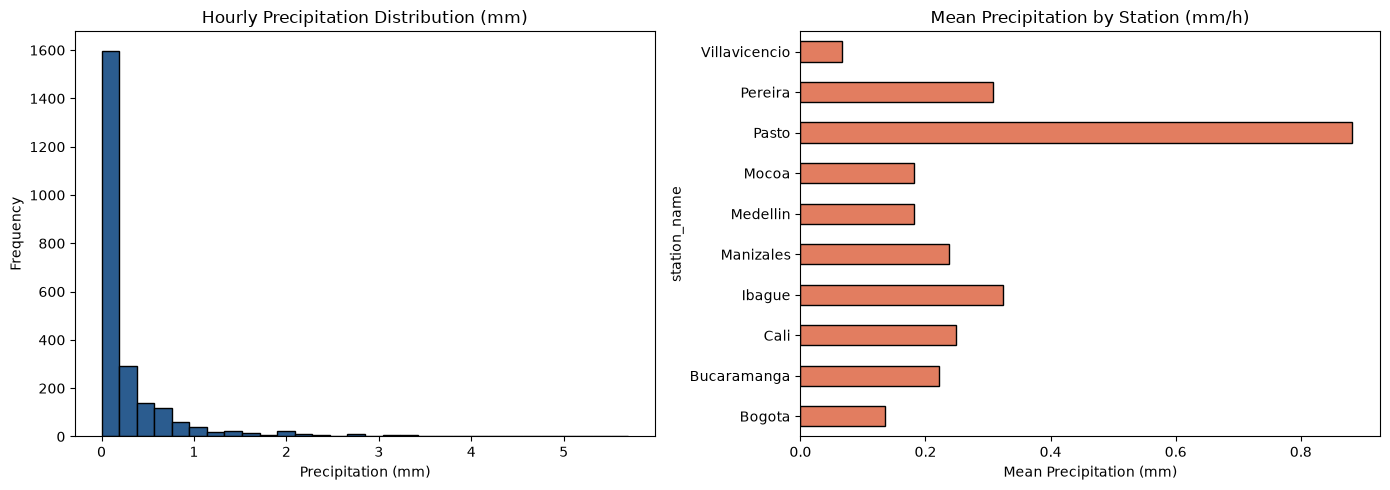

In [5]:
# Distribution plot of hourly precipitation
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df_rain['precipitation_mm'].plot(kind='hist', bins=30, ax=axes[0], color='#2b5c8f', edgecolor='black')
axes[0].set_title('Hourly Precipitation Distribution (mm)')
axes[0].set_xlabel('Precipitation (mm)')
axes[0].set_ylabel('Frequency')

# Average precipitation per station
df_rain.groupby('station_name', observed=True)['precipitation_mm'].mean().plot(
    kind='barh', ax=axes[1], color='#e27d60', edgecolor='black'
)
axes[1].set_title('Mean Precipitation by Station (mm/h)')
axes[1].set_xlabel('Mean Precipitation (mm)')

plt.tight_layout()
plt.show()


## 5. NLP Text Preprocessing on Landslide Narratives (`landslides_*.parquet`)
We load the historical landslide inventory to inspect the NLP pipeline results: cleaned text, removed stopwords, and token frequency distributions.


In [6]:
landslide_files = [f for f in parquet_files if 'landslides' in f.name]
assert len(landslide_files) > 0, 'No landslides parquet file found'
target_landslides = landslide_files[-1]

df_landslides = pd.read_parquet(target_landslides)
print(f'Loaded {len(df_landslides)} landslide records.')
print('Columns:', list(df_landslides.columns))

# Display comparison of raw vs cleaned NLP text
# Missing values are flagged, never imputed: no invented countries or zero deaths
print('Events without country (kept, flagged):', int(df_landslides['country_missing'].sum()))
print('Events without fatality count (kept as null):', int(df_landslides['fatality_missing'].sum()))
print('Events with unknown time (00:00):', int(df_landslides['is_time_unknown'].sum()))
display(df_landslides[df_landslides['event_id'].astype(str) == '10790'][
    ['event_id', 'event_date', 'timestamp_utc', 'country_name', 'country_missing', 'fatality_count', 'fatality_outlier_iqr']])

# Display comparison of raw vs cleaned NLP text
sample_nlp = df_landslides[['country_name', 'admin_division_name', 'raw_text_narrative', 'cleaned_text_nlp', 'token_count']].head(5)
sample_nlp


Loaded 109 landslide records.
Columns: ['source_name', 'source_link', 'event_id', 'event_date', 'event_time', 'event_title', 'event_description', 'location_description', 'location_accuracy', 'landslide_category', 'landslide_trigger', 'landslide_size', 'landslide_setting', 'fatality_count', 'injury_count', 'storm_name', 'photo_link', 'notes', 'event_import_source', 'event_import_id', 'country_name', 'country_code', 'admin_division_name', 'admin_division_population', 'gazeteer_closest_point', 'gazeteer_distance', 'submitted_date', 'created_date', 'last_edited_date', 'longitude', 'latitude', 'event_date_parsed', 'is_time_unknown', 'timestamp_utc', 'fatality_missing', 'country_missing', 'raw_text_narrative', 'cleaned_text_nlp', 'tokens_nlp', 'token_count', 'fatality_outlier_iqr', 'fatality_outlier_zscore', 'fatality_zscore', '_bronze_source_file', '_processed_at_utc', '_record_hash']
Events without country (kept, flagged): 8
Events without fatality count (kept as null): 5
Events with unkno

,event_id,event_date,timestamp_utc,country_name,country_missing,fatality_count,fatality_outlier_iqr
102,10790,03/25/2017 05:32:00 PM,2017-03-25 22:32:00+00:00,NaN,True,329,True


,country_name,admin_division_name,raw_text_narrative,cleaned_text_nlp,token_count
0,Colombia,Risaralda,"Dosquebradas, Risaralda The explosion at a pip...",dosquebradas risaralda the explosion at a pipe...,16
1,Colombia,Santander,"California village, Sutara valley, NE of Bucar...",california village sutara valley ne of bucaram...,64
2,Colombia,Nariño,"San Antonio(?) de Chuza, El Tambo, Narino The ...",san antonio de chuza el tambo narino the death...,56
3,Colombia,Huila,bus route from Neiva to San Vicente According ...,bus route from neiva to san vicente according ...,26
4,Colombia,Córdoba,"San Juan , Cordoba province BOGOTA, April 24 (...",san juan cordoba province bogota april upi a m...,48


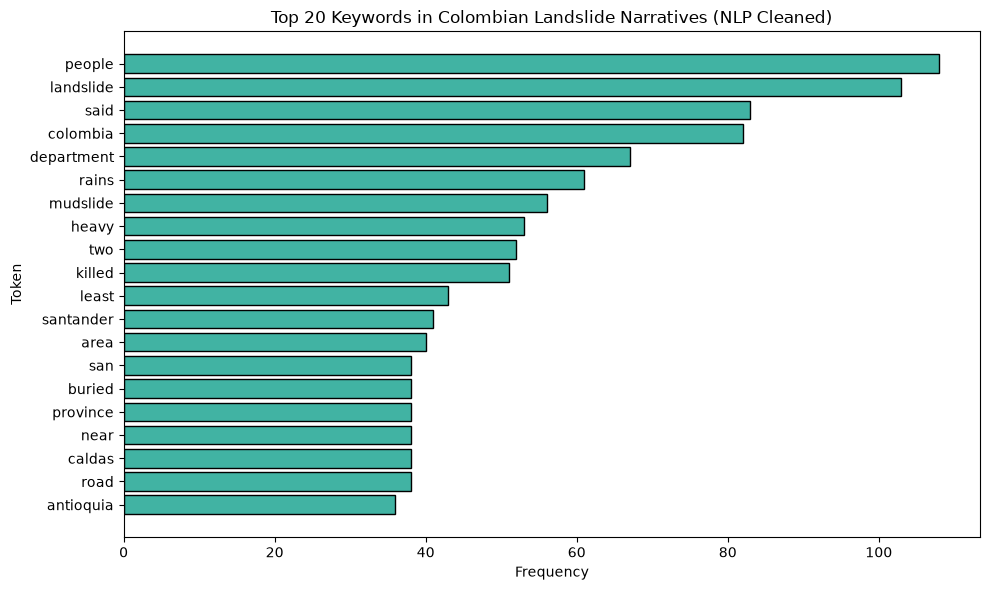

In [7]:
from collections import Counter

all_tokens = []
for token_list in df_landslides['tokens_nlp']:
    if isinstance(token_list, (list, tuple, np.ndarray)):  # Parquet returns numpy arrays
        all_tokens.extend(token_list)

token_counts = Counter(all_tokens).most_common(20)
token_df = pd.DataFrame(token_counts, columns=['Keyword', 'Frequency'])

plt.figure(figsize=(10, 6))
plt.barh(token_df['Keyword'][::-1], token_df['Frequency'][::-1], color='#41b3a3', edgecolor='black')
plt.title('Top 20 Keywords in Colombian Landslide Narratives (NLP Cleaned)')
plt.xlabel('Frequency')
plt.ylabel('Token')
plt.tight_layout()
plt.show()


## 6. NASA LHASA Hazard per Station (`lhasa_hazard_*.parquet`)
The scraper finds the newest nowcast GeoTIFF in the directory listing and reads only a +/-0.125 deg
window around each monitoring station (HTTP range requests through GDAL /vsicurl/).


In [8]:
lhasa_files = [f for f in parquet_files if 'lhasa' in f.name]
assert len(lhasa_files) > 0, 'No LHASA parquet file found'
df_lhasa = pd.read_parquet(lhasa_files[-1])

print(f'LHASA Silver rows: {len(df_lhasa)}')
df_lhasa.drop(columns=['_record_hash'], errors='ignore')


LHASA Silver rows: 10


,station_name,department,latitude,longitude,nominal_issue_time,valid_pixel_count,lhasa_max,lhasa_mean,lhasa_p90,has_high_hazard,_bronze_source_file,_processed_at_utc
0,Bogota,Cundinamarca,4.6097,-74.0817,2026-11-19 00:00:00+00:00,548,0.0553,0.0078,0.0117,False,nasa_lhasa_20261121_064020.json,2026-11-21 07:00:11.904665+00:00
1,Medellin,Antioquia,6.2442,-75.5812,2026-11-19 00:00:00+00:00,830,0.1694,0.0585,0.1136,False,nasa_lhasa_20261121_064020.json,2026-11-21 07:00:11.904665+00:00
2,Cali,Valle del Cauca,3.4516,-76.5320,2026-11-19 00:00:00+00:00,461,0.0810,0.0435,0.0721,False,nasa_lhasa_20261121_064020.json,2026-11-21 07:00:11.904665+00:00
3,Manizales,Caldas,5.0689,-75.5174,2026-11-19 00:00:00+00:00,898,0.0995,0.0146,0.0269,False,nasa_lhasa_20261121_064020.json,2026-11-21 07:00:11.904665+00:00
4,Pereira,Risaralda,4.8133,-75.6961,2026-11-19 00:00:00+00:00,745,0.0770,0.0088,0.0130,False,nasa_lhasa_20261121_064020.json,2026-11-21 07:00:11.904665+00:00
5,Ibague,Tolima,4.4389,-75.2322,2026-11-19 00:00:00+00:00,781,0.0217,0.0064,0.0168,False,nasa_lhasa_20261121_064020.json,2026-11-21 07:00:11.904665+00:00
6,Bucaramanga,Santander,7.1254,-73.1198,2026-11-19 00:00:00+00:00,863,0.0077,0.0045,0.0061,False,nasa_lhasa_20261121_064020.json,2026-11-21 07:00:11.904665+00:00
7,Pasto,Narino,1.2136,-77.2811,2026-11-19 00:00:00+00:00,876,0.3077,0.0844,0.1625,False,nasa_lhasa_20261121_064020.json,2026-11-21 07:00:11.904665+00:00
8,Mocoa,Putumayo,1.1528,-76.6521,2026-11-19 00:00:00+00:00,878,0.0285,0.0113,0.0234,False,nasa_lhasa_20261121_064020.json,2026-11-21 07:00:11.904665+00:00
9,Villavicencio,Meta,4.1420,-73.6266,2026-11-19 00:00:00+00:00,370,0.0135,0.0091,0.0130,False,nasa_lhasa_20261121_064020.json,2026-11-21 07:00:11.904665+00:00


## 7. Historical daily rainfall (`rainfall_historical_*.parquet`, Open-Meteo ERA5 archive)
Every record in the Silver layer must trace back to its origin in the Bronze layer.


In [9]:
hist_files = [f for f in parquet_files if f.name.startswith('rainfall_historical_')]
df_hist = pd.concat([pd.read_parquet(f) for f in hist_files], ignore_index=True)
print(f'{len(df_hist):,} station-days from {df_hist.date_utc.min():%Y-%m-%d} to {df_hist.date_utc.max():%Y-%m-%d} '
      f'in {df_hist._bronze_source_file.nunique()} yearly Bronze files')
print('Missing daily totals (kept null):', int(df_hist['precip_24h_missing'].sum()))
summary = df_hist.groupby('station_name', observed=True).agg(
    mean_daily_mm=('precip_24h_mm', 'mean'), p95_daily_mm=('precip_24h_mm', lambda s: s.quantile(0.95)),
    max_daily_mm=('precip_24h_mm', 'max'), max_7d_mm=('precip_7d_mm', 'max')).round(1)
summary.sort_values('mean_daily_mm', ascending=False)


36,530 station-days from 2016-01-01 to 2025-12-31 in 10 yearly Bronze files
Missing daily totals (kept null): 0


,mean_daily_mm,p95_daily_mm,max_daily_mm,max_7d_mm
station_name,,,,
Manizales,18.8,55.5,161.5,619.4
Bucaramanga,11.7,38.8,177.9,383.3
Mocoa,11.7,40.4,181.1,490.3
Pereira,11.5,41.3,125.7,484.8
Villavicencio,11.2,39.9,211.8,403.8
Ibague,11.1,34.8,71.8,323.6
Pasto,9.9,29.5,75.0,223.3
Cali,9.2,28.4,93.6,242.5
Medellin,6.1,18.5,70.0,150.3


## 8. Data Lineage and Traceability Audit
Every record in the Silver layer must trace back to its origin in the Bronze layer.


In [10]:
lineage_summary = pd.DataFrame([
    {
        'Dataset': 'Rainfall (Open-Meteo)',
        'Bronze Source File': df_rain['_bronze_source_file'].iloc[0],
        'Processed At (UTC)': str(df_rain['_processed_at_utc'].iloc[0]),
        'Sample Record Hash': df_rain['_record_hash'].iloc[0][:16] + '...',
        'Total Rows': len(df_rain),
    },
    {
        'Dataset': 'Landslides (NASA GLC)',
        'Bronze Source File': df_landslides['_bronze_source_file'].iloc[0],
        'Processed At (UTC)': str(df_landslides['_processed_at_utc'].iloc[0]),
        'Sample Record Hash': df_landslides['_record_hash'].iloc[0][:16] + '...',
        'Total Rows': len(df_landslides),
    },
    {
        'Dataset': 'LHASA Hazard (NASA)',
        'Bronze Source File': df_lhasa['_bronze_source_file'].iloc[0],
        'Processed At (UTC)': str(df_lhasa['_processed_at_utc'].iloc[0]),
        'Sample Record Hash': df_lhasa['_record_hash'].iloc[0][:16] + '...',
        'Total Rows': len(df_lhasa),
    },
])
lineage_summary


,Dataset,Bronze Source File,Processed At (UTC),Sample Record Hash,Total Rows
0,Rainfall (Open-Meteo),openmeteo_forecast_20261121_071138.json,2026-11-21 07:17:42.022289+00:00,16c35a6962eb35a6...,2400
1,Landslides (NASA GLC),nasa_glc_20261121_064020.json,2026-11-21 07:00:11.854072+00:00,8a9ac8cbb0c62457...,109
2,LHASA Hazard (NASA),nasa_lhasa_20261121_064020.json,2026-11-21 07:00:11.904665+00:00,d94beb28378a0f2d...,10


## 9. Conclusion
The Silver layer implementation satisfies all Workshop #2 requirements:
- **Type safety:** Strict schemas enforced with PyArrow and Pandas.
- **Data Quality:** Outlier flags (never deletions), conservative null handling (missing values are flagged,
  not invented) and deduplication applied deterministically.
- **NLP Readiness:** Cleaned narratives and token lists ready for semantic hazard classification.
- **Traceability:** Full lineage tracking from Bronze JSON to Silver Parquet.
